<a href="https://colab.research.google.com/github/DanielV-13/ADFM---PL_02_inductive_bias_parameterized_nns.ipynb/blob/main/ADFM_PL_02_inductive_bias_parameterized_nns.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

<a href="https://colab.research.google.com/github/vischia/adfm_2024-2025/blob/master/practice_2_a_parameterized_nns.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Análisis de Datos en Física Moderna

(C)2025 Pietro Vischia, vischia@uniovi.es

## PL 2: machine learning paramétrico

In this practice, you'll implement the parameterized machine learning algorithm devised by Baldi et al., [1601.07913](https://arxiv.org/abs/1601.07913)

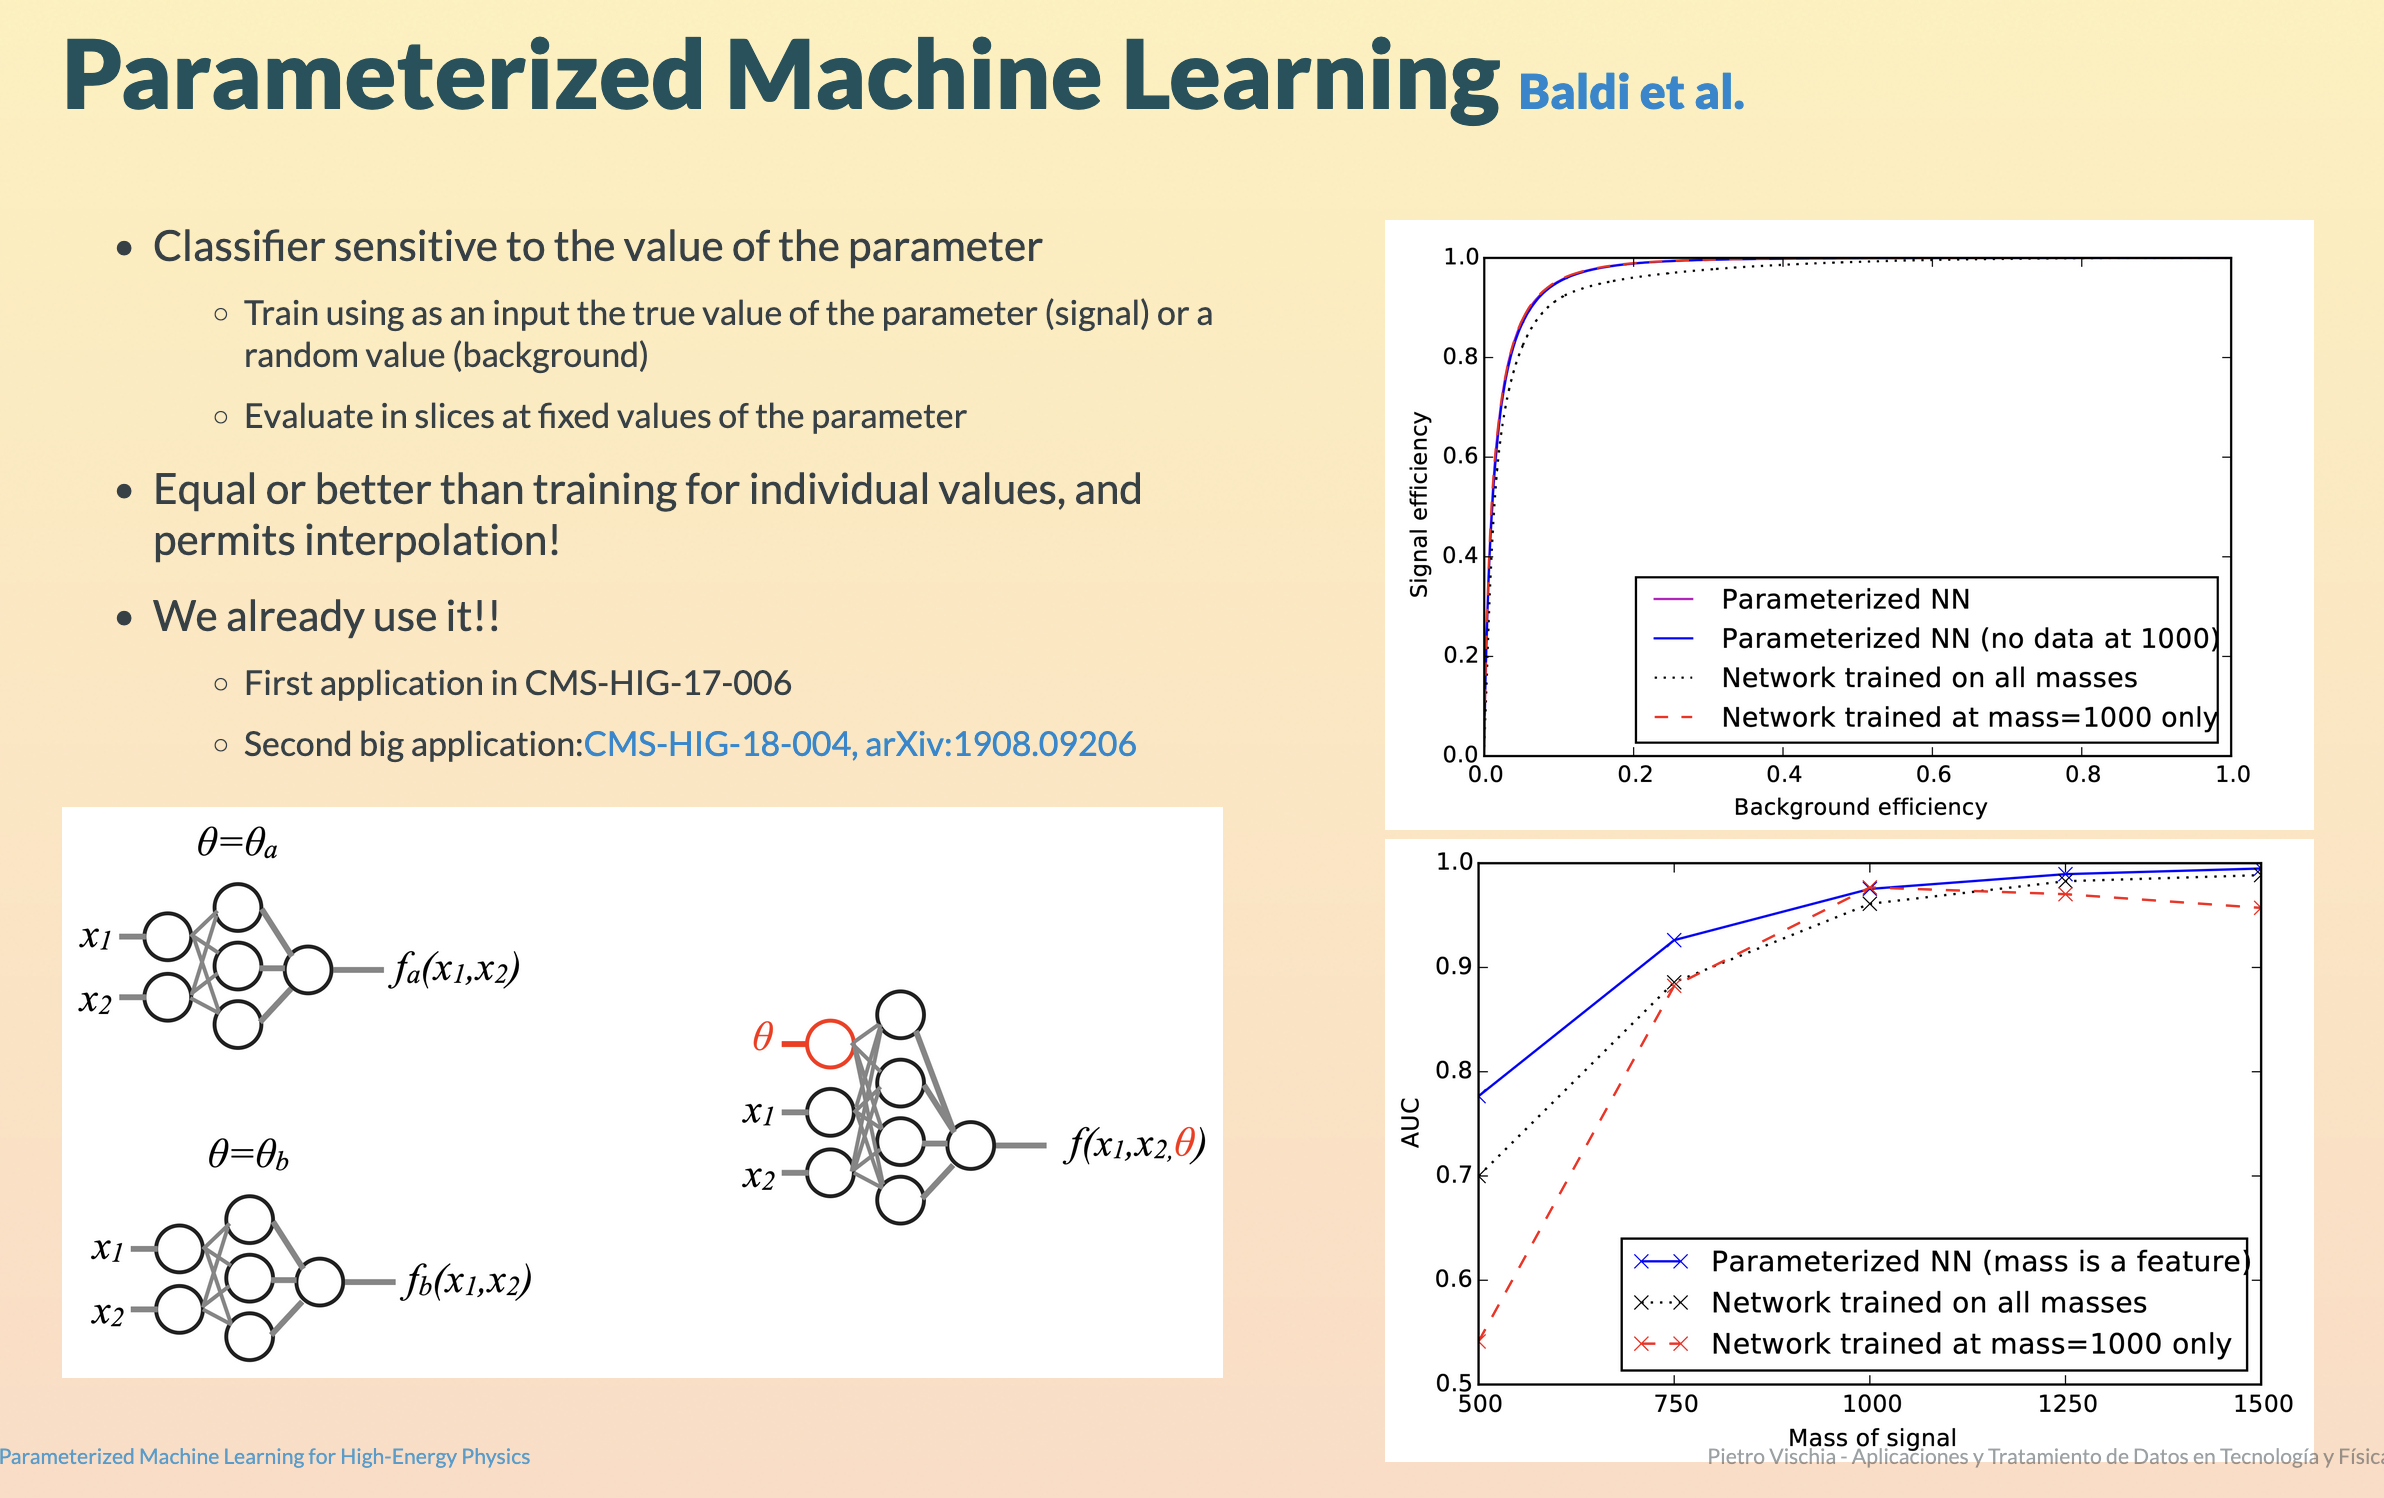

# 🧠 Fundamentos Teóricos: Aprendizaje Automático Paramétrico (Parameterized ML)

En problemas clásicos de clasificación supervisada en física de altas energías (HEP), el objetivo principal es separar eventos de **Señal ($S$)** de eventos de **Fondo ($B$)**.

* **Señal ($S$):** Eventos generados por la presencia de una nueva partícula o resonancia pesada de masa hipotética $M_X$.
* **Fondo ($B$):** Eventos ruidosos generados por procesos conocidos del Modelo Estándar (por ejemplo, la producción de pares de quarks top $t\bar{t}$).

---

### 1. El Dilema Tradicional vs. El Enfoque Paramétrico

#### A. Enfoque Tradicional (Red Neuronal No Paramétrica)
En un clasificador estándar, entrenamos un modelo $f(\mathbf{x})$ utilizando únicamente el vector de características cinemáticas observadas en la colisión:
$$\mathbf{x} = (x_1, x_2, \dots, x_N) \in \mathbb{R}^N$$

* **Limitación:** Si la partícula hipotética tiene una masa de $M_X = 750\text{ GeV}$, el modelo aprende una frontera de decisión específica para $750\text{ GeV}$. Si posteriormente queremos probar hipótesis para $M_X = 500\text{ GeV}, 600\text{ GeV}$ o $1000\text{ GeV}$, se debe entrenar una red neuronal independiente desde cero para cada punto de masa.
* **Inconveniente:** Requiere entrenar, gestionar y almacenar decenas de modelos aislados, sin posibilidad de compartir conocimiento cinemático entre diferentes hipótesis de masa.

#### B. Enfoque Paramétrico (Baldi et al., 2016)
La solución introducida por Baldi et al. consiste en extender el vector de entrada incorporando el parámetro físico de interés (la masa $\theta = M_X$) directamente como una característica (feature) de entrada adicional:
$$\mathbf{x}_{\text{extended}} = (\mathbf{x}, \theta) = (x_1, x_2, \dots, x_N, \theta) \in \mathbb{R}^{N+1}$$

Un **único clasificador** aprende la función mapeada:
$$f(\mathbf{x}, \theta): \mathbb{R}^{N+1} \rightarrow [0, 1]$$

De este modo, la red neuronal no solo aprende las distribuciones cinemáticas de las partículas, sino también **cómo estas distribuciones evolucionan continuamente en función de la masa $\theta$**.

### 2. Formulación de los Datos de Entrenamiento (El "Truco" de Baldi)

Para que la red paramétrica aprenda a generalizar e interpolar correctamente a lo largo de todo el espectro del parámetro $\theta$, los datos se estructuran siguiendo una regla de muestreo estricta durante la fase de entrenamiento:

1. **Para Eventos de Señal ($S$):**
   * El vector de características $\mathbf{x}$ se toma de las colisiones simuladas.
   * El parámetro de entrada $\theta$ se iguala exactamente a la **masa real hipotética** de la señal en esa simulación ($\theta = M_{\text{true}}$).

2. **Para Eventos de Fondo ($B$):**
   * El trasfondo físico no posee una masa de resonancia real asociada (es un continuo).
   * **El Truco:** A cada evento de fondo se le asigna un valor de masa $\theta$ **muestreado aleatoriamente** de la misma distribución de masas usada para los eventos de señal ($\theta \sim P(M_{\text{signal}})$).

| Tipo de Evento | Etiqueta ($y$) | Vector de Entrada | Valor del Parámetro ($\theta$) |
| :--- | :---: | :---: | :--- |
| **Señal ($S$)** | `1` | $(\mathbf{x}, \theta)$ | Masa nominal real ($M_{\text{true}}$) |
| **Fondo ($B$)** | `0` | $(\mathbf{x}, \theta)$ | Masa aleatoria seleccionada de $P(M_{\text{signal}})$ |

---

### 3. Ventajas Clave del Aprendizaje Paramétrico

* **Capacidad de Interpolación:** Si entrenamos el modelo con masas fijas (ej. $500, 750, 1000\text{ GeV}$), la red puede evaluar eficientemente colisiones para masas intermedia no vistas durante el entrenamiento (ej. $650\text{ GeV}$) mediante una superficie de decisión suave y continua.
* **Mayor Rendimiento y Eficiencia:** Al entrenar con todo el conjunto de datos acoplado, la red aprovecha estadísticas más grandes, logrando un valor de AUC (Área Bajo la Curva ROC) igual o superior al de múltiples redes entrenadas de forma individual.
* **Ahorro Computacional:** Se reemplaza el mantenimiento de $K$ modelos independientes por la optimización de un único modelo global.

### 📊 Plan de Trabajo y Objetivos en este Notebook

A lo largo de las celdas de código de este cuaderno (`PL_02_inductive_bias_parameterized_nns.ipynb`), implementaremos y validaremos los siguientes pasos:

-HEP es HIGH ENERGY PHYSICS

1. **Carga e Inspección de Datos (HEPMASS Dataset):**
   * Análisis del dataset que contiene 27 características (22 de bajo nivel y 5 de alto nivel) junto con la variable `mass`.
   * Visualización de histogramas de distribución y matrices de correlación para señal y fondo.

2. **Preprocesamiento y Formato de Tensores:**
   * Organización del vector de entrada incorporando el escalar de masa $\theta$.

3. **Diseño de la Arquitectura de la Red Neuronal desde Cero (NumPy & PyTorch):**
   * Definición de capas densas (capas ocultas), funciones de activación y la capa de salida logit/sigmoide.

4. **Entrenamiento y Evaluación de Desempeño:**
   * Evaluación de la superficie de decisión mediante curvas ROC y métricas AUC evaluando la capacidad de la red para discriminar eventos en puntos de masa específicos e interpolados.

In [1]:
# Uncomment and run this if you are running on Colab (remove only the "#", keep the "!").
# You can run it anyway, but it will do nothing if you have already installed all dependencies
# (and it will take some time to tell you it is not gonna do anything)


from google.colab import drive
drive.mount('/content/drive')
%cd "/content/drive/MyDrive/"
! git clone https://github.com/vischia/atdtf.git
%cd atdtf
!pwd
!ls
!pip install livelossplot shap

Mounted at /content/drive
/content/drive/MyDrive
fatal: destination path 'atdtf' already exists and is not an empty directory.
/content/drive/MyDrive/atdtf
/content/drive/MyDrive/atdtf
figs  PA_01_autodiff.ipynb	 PL_02_trackml.ipynb  requirements.txt
old   PL_01_dataChallenge.ipynb  README.md	      requirements_venv.txt
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 639.0/639.0 kB 12.6 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.9/4.9 MB 81.9 MB/s  0:00:00
  Attempting uninstall: traitlets
    Found existing installation: traitlets 5.7.1
    Uninstalling traitlets-5.7.1:
      Successfully uninstalled traitlets-5.7.1
  Attempting uninstall: psutil
    Found existing installation: psutil 5.9.5
    Uninstalling psutil-5.9.5:
      Successfully uninstalled psutil-5.9.5
  Attempting uninstall: ipython
    Found existing installation: ipython 7.34.0
    Uninstalling ipython-7.34.0:
      Successfully uninstalled ipython-7.34.0
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10/10 [

In [2]:
import matplotlib
%matplotlib inline
import matplotlib.pyplot as plt
import glob
import os
import re
import math
import socket
import json
import pickle
import gzip
import copy
import array
import numpy as np
import numpy.lib.recfunctions as recfunc

from scipy.optimize import newton
from scipy.stats import norm

import datetime
from timeit import default_timer as timer

from sklearn.model_selection import train_test_split
from sklearn.utils import shuffle
from sklearn.metrics import roc_curve, auc, accuracy_score
from sklearn.tree import export_graphviz
from sklearn.inspection import permutation_importance
try:
    # See #1137: this allows compatibility for scikit-learn >= 0.24
    from sklearn.utils import safe_indexing
except ImportError:
    from sklearn.utils import _safe_indexing

from livelossplot import PlotLossesKeras

import torch

import pandas as pd


In [3]:
INPUT_FOLDER = './'
HAVE_GPU = True


We will use the [HEP-mass dataset](http://archive.ics.uci.edu/ml/datasets/hepmass) hosted by UCIrvine together with many other datasets used to test machine learning applications.

This dataset provides top pair production events as a background, and the classification task is to separate them from events generated by a high-mass resonance (masses of 500--1000 GeV). The larger the mass, the easiest the prediction task.

The label is 1 for signal, and 0 for background. There are 27 normalized features, divided into 22 low-level ones and 5 high-level ones. Because of time constraints, we won't explore the topic of pitting low-level and high-level features against each other or of mixing them, but you are encouraged to play with them later.

<img src="https://github.com/vischia/adfm_2024-2025/blob/master/figs/hepmass.png?raw=1" alt="masses from 1601.07913" style="width:50%;"/>

(figure from [1601.07913](https://arxiv.org/abs/1601.07913))

### 📂 El Conjunto de Datos HEPMASS (HIGH ENERGY PHYSICS) : Descripción General

Utilizamos el dataset **HEPMASS** alojado en el repositorio de la Universidad de California en Irvine (UCI), un estándar ampliamente empleado para evaluar aplicaciones de Machine Learning en física experimental.

* **La Tarea de Clasificación:** El problema consiste en separar eventos de **fondo (background)** —compuestos por la producción estándar de pares de quarks top ($t\bar{t}$)— de eventos de **señal**, los cuales corresponden a una hipotética resonancia de alta masa (con masas en el rango de $500\text{--}1000\text{ GeV}$).
* **Estructura de las Etiquetas:** Las etiquetas (`label`) se definen como `1` para los eventos de señal y `0` para los eventos de fondo.
* **Características (Features):** El conjunto cuenta con **27 características normalizadas**, divididas estructuralmente en:
  * **22 características de bajo nivel:** Mediciones directas e individuales de las partículas registradas en el detector.
  * **5 características de alto nivel:** Variables físicas globales calculadas a partir de las mediciones anteriores.

### ⚡ La Dificultad Física: Relación entre Masa y Predicción

Como regla fundamental en física de altas energías, **cuanto mayor es la masa de la partícula buscada, más fácil es la tarea de predicción para el algoritmo**.

* **Razón Cinemática:** Las partículas de resonancia con masas muy elevadas se desintegran liberando una cantidad de energía drásticamente mayor. Como resultado, sus productos de desintegración escapan con momentos transversales y energías cinemáticas mucho más extremas.
* **Separación del Fondo:** Estas firmas cinemáticas extremas contrastan de manera muy marcada con el fondo de producción de pares de quarks top (el cual tiende a agruparse en regiones de menor energía), permitiendo que los modelos de Machine Learning distingan la señal con mayor precisión a medida que incrementa la masa nominal.

### 📈 Análisis Visual de la Distribución de Masas ($m_{WWbb}$)

El gráfico de distribuciones nos permite visualizar el comportamiento físico subyacente y la separación entre los eventos:

* **Área Gris Sólida (Background / Fondo):** Representa el ruido de fondo del Modelo Estándar. Se observa que se concentra densamente en la región de masas más bajas (hacia el extremo izquierdo del espectro).
* **Líneas de Colores (Señales $m_X$):** Cada trazo coloreado representa la distribución esperada para una masa de resonancia fija, escalando desde $m_X = 500\text{ GeV}$ (azul) hasta $m_X = 1500\text{ GeV}$ (magenta).
* **Implicación para el Modelo Paramétrico:** A medida que la masa $m_X$ aumenta, los picos de las curvas de señal se desplazan progresivamente hacia la derecha. Una red neuronal paramétrica aprovecha esta evolución continua al recibir la masa $\theta$ como entrada, modelando de forma unificada todo el espacio cinemático sin requerir modelos independientes por cada color.

You can download the data from:

[https://www.hep.uniovi.es/vischia/adfm/](https://www.hep.uniovi.es/vischia/adfm/)

by hand or by running:

In [7]:
downloadMinidata=True

if downloadMinidata:
    !mkdir data
    !cd data
    # If the uniovi.es link doesn't work, uncomment the CERN one
    !wget https://cern.ch/vischia/adfm/data_for_practica2.zip
    #!wget https://www.hep.uniovi.es/vischia/adfm/data_for_practica2.zip
    !unzip data_for_practica2.zip
    !cd ..

mkdir: cannot create directory ‘data’: File exists
--2026-10-27 18:21:40--  https://cern.ch/vischia/adfm/data_for_practica2.zip
Resolving cern.ch (cern.ch)... 188.184.77.250, 2001:1458:d00:3c::100:2f9
Connecting to cern.ch (cern.ch)|188.184.77.250|:443... connected.
HTTP request sent, awaiting response... 302 Found
Location: https://vischia.web.cern.ch/adfm/data_for_practica2.zip [following]
--2026-10-27 18:21:41--  https://vischia.web.cern.ch/adfm/data_for_practica2.zip
Resolving vischia.web.cern.ch (vischia.web.cern.ch)... 188.184.111.229, 188.184.96.45, 137.138.55.232, ...
Connecting to vischia.web.cern.ch (vischia.web.cern.ch)|188.184.111.229|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 57367876 (55M) [application/zip]
Saving to: ‘data_for_practica2.zip’

data_for_practica2. 100%[===================>]  54.71M  13.7MB/s    in 4.7s    

2026-10-27 18:21:47 (11.7 MB/s) - ‘data_for_practica2.zip’ saved [57367876/57367876]

Archive:  data_for_practica2.zip
 

**NO EJECUTAR LA SIGUIENTE CELDA**

In [ ]:
# Do not set these to True in the live tutorial,
# otherwise you will clog the conference venue connection for nothing.
# The skimmed files are already included in this repository

createLowMass=False
createHighMass=False

if createLowMass:
    ! wget http://archive.ics.uci.edu/ml/machine-learning-databases/00347/not1000_train.csv.gz
    ! wget http://archive.ics.uci.edu/ml/machine-learning-databases/00347/not1000_test.csv.gz
    cols=["label", "f0", "f1", "f2", "f3", "f4", "f5", "f6", "f7", "f8", "f9", "f10", "f11", "f12", "f13",
          "14f", "15f", "f16", "f17", "f18", "f19", "f20", "f21", "f22", "f23", "f24", "f25", "f26", "mass"]

    train_set = pd.read_csv('./not1000_train.csv.gz', index_col=False, names=cols, header=0)
    test_set = pd.read_csv('./not1000_test.csv.gz', index_col=False, names=cols, header=0)

    # Here we exploit the fact that the background has an assigned random mass sampled from
    # the same set than that of the signal. Therefore we can just require the mass to be 500
    # without having to check for the signal and background label.
    # A final test ensures the amount of events is approximately the same.

    # In the data set, for some reason the "mass 500" is encoded as 499.999969, but "==499.999969" does not
    # match any entry. We will therefore use "<501" to select the events with mass=500

    train_set=train_set[train_set['mass']<501]
    test_set=test_set[test_set['mass']<501]

    print('Full train', len(train_set),
          len(train_set[train_set['label']==1]),
          len(train_set[train_set['label']==0]))
    print('Full test', len(test_set),
          len(test_set[test_set['label']==1]),
          len(test_set[test_set['label']==0]))

    train_set_temp=train_set.head(10000)
    test_set_temp=test_set.head(10000)

    train_set_temp.to_csv('data/not1000_train_medium.csv')
    test_set_temp.to_csv('data/not1000_test_medium.csv')


    train_set_temp=train_set.head(1000)
    test_set_temp=test_set.head(1000)

    train_set_temp.to_csv('data/not1000_train_small.csv')
    test_set_temp.to_csv('data/not1000_test_small.csv')


if createHighMass: # Not needed, I included the small and medium sets in the github repository

    ! wget http://archive.ics.uci.edu/ml/machine-learning-databases/00347/1000_train.csv.gz
    ! wget http://archive.ics.uci.edu/ml/machine-learning-databases/00347/1000_test.csv.gz
    # This needs to be run only once
    cols=[label_name, "f0", "f1", "f2", "f3", "f4", "f5", "f6", "f7", "f8", "f9", "f10", "f11", "f12", "f13", "14f", "15f", "f16", "f17", "f18", "f19", "f20", "f21", "f22", "f23", "f24", "f25", "f26"]
    train_set = pd.read_csv('./1000_train.csv.gz', index_col=False, names=cols, header=0)
    test_set = pd.read_csv('./1000_test.csv.gz', index_col=False, names=cols, header=0)

    # Randomly pick 10000 events from the full data set
    train_set_temp=train_set.head(10000)
    test_set_temp=test_set.head(10000)

    train_set_temp.to_csv('data/1000_train_medium.csv')
    test_set_temp.to_csv('data/1000_test_medium.csv')

    # Randomly pick 1000 events from the full data set
    train_set_temp=train_set.head(1000)
    test_set_temp=test_set.head(1000)

    train_set_temp.to_csv('data/1000_train_small.csv')
    test_set_temp.to_csv('data/1000_test_small.csv')


**CARGA LOS DATOS, Y LOS LEE CON PANDAS**

In [14]:
# Load the chosen set
# Carga los conjuntos de datos desde la carpeta correcta
train_set = pd.read_csv('data_for_practica2/not1000_750_train_medium.csv', index_col=False)
test_set = pd.read_csv('data_for_practica2/not1000_750_test_medium.csv', index_col=False)

# Drop mass info, if needed (the "1000..." files don't have a 'mass' column)
if 'mass' in train_set.columns:
    train_set=train_set.drop(['mass'], axis=1)
    test_set=test_set.drop(['mass'], axis=1)
train_set.head()

,Unnamed: 0,label,f0,f1,f2,f3,f4,f5,f6,f7,...,f17,f18,f19,f20,f21,f22,f23,f24,f25,f26
0,1,1.0,-1.401979,-0.942620,1.049402,1.637764,1.681190,-0.005984,0.733926,-0.476641,...,-0.815440,-0.822903,0.156014,-0.197154,1.743123,0.361093,-0.941934,0.026127,1.396366,-0.123928
1,12,0.0,-0.646328,0.132367,0.864149,0.596158,0.266139,-1.054221,-0.801212,0.231854,...,1.226331,-1.368451,-0.189723,-1.710976,-0.573682,-0.800589,-0.594036,-0.377533,-0.113845,-1.300184
2,13,1.0,-0.093261,0.168337,1.287353,0.319592,-1.359426,1.574625,0.988875,-0.268706,...,-0.815440,1.634929,-0.067125,-1.548938,1.743123,-0.015264,-0.080968,0.756942,0.879847,0.218808
3,16,1.0,1.205673,1.103310,-1.132657,-1.284128,-0.823548,0.850488,0.943595,0.516031,...,1.226331,0.383688,-0.162711,1.030514,-0.573682,-0.739276,-0.147738,-0.270474,-0.256237,0.318978
4,19,0.0,-1.134711,1.257473,-0.419845,-0.848054,-1.568315,-1.054221,-0.144344,-0.077036,...,-0.815440,-0.278497,0.340343,0.306618,-0.573682,-0.384413,-0.364842,-0.309805,-0.673690,-0.957803


In [15]:
print('Training set has', len(train_set), 'entries (', len(train_set[train_set['label']==1]), 'signal entries, ',
      len(train_set[train_set['label']==0]), ' background entries)')

Training set has 10000 entries ( 5002 signal entries,  4998  background entries)


### 📊 Resumen de Carga y Análisis Preliminar del Dataset

En estas celdas se han llevado a cabo los siguientes procesos fundamentales:

* **Carga de los conjuntos de datos:** Se han importado los archivos CSV correspondientes (`not1000_750_train_medium.csv` y `not1000_750_test_medium.csv`) utilizando la librería `pandas` para estructurar la información en dataframes.
* **Limpieza de variables de masa:** Se ha incluido una condición de seguridad para eliminar la columna de masa (`mass`) del conjunto de datos en caso de que esté presente, enfocando el entrenamiento en las variables cinemáticas o de bajo nivel.
* **Estructura y dimensiones iniciales:**
  * El dataset cuenta con **29 columnas** en total.
  * La columna **`label`** define la etiqueta de clase (`1.0` para eventos de **señal** y `0.0` para eventos de **fondo** o *background*).
  * Las variables restantes (`f0`, `f1`, `f2`, ..., `f23`, etc.) representan las características físicas de entrada.
* **Balance de clases (Entrenamiento):**
  * El conjunto de entrenamiento consta de exactamente **10,000 entradas**.
  * Está perfectamente equilibrado para evitar sesgos en el aprendizaje automático: **5,002** entradas de señal y **4,998** entradas de fondo.

### Split the data set into training and test set

When we train a machine learning algorithm, we are trying to solve an interpolation problem (*find the function of the input features that provides the best approximation of the true function*) by also requiring that the solution generalizes sufficiently well (*the interpolating function must also predict correctly the value of the true function for new, unseen data*).


When we have a labelled dataset, we will therefore split it into: a *training set*, which we will use to train the machine learning algorithm; a *test set*, which we will use to evaluate the performance of the algorithm for various realizations of the algorithm (e.g. tuning hyperparameters); and an *application set*, which are the data we are really interested in studying in the end.

For many applications, when the amount of hyperparameters tuning is moderate, application set and test set can be collapsed into a single set (usually called *test set*). This is what we will do in this tutorial.

![Blah](https://github.com/vischia/adfm_2024-2025/blob/master/figs/trainingNetwork.png?raw=1)

(Image: P. Vischia, [doi:10.5281/zenodo.6373442](https://doi.org/10.5281/zenodo.6373442))

## 🧠 Conceptos Clave: Interpolación, Generalización y Gestión de Datos

### 1. El problema de interpolación y generalización
* **El objetivo del modelo:** Entrenar un algoritmo de machine learning equivale a resolver un **problema de interpolación**, es decir, encontrar una función basada en las características de entrada que ofrezca la mejor aproximación a la función real.
* **Generalización:** No basta con que el modelo memorice los datos; el requisito clave es que **generalice**, prediciendo de forma correcta los resultados para datos nuevos y totalmente no vistos.

### 2. División de los datos (*Data Split*)
Para lograr una evaluación justa y evitar sesgos, el dataset se divide tradicionalmente en tres partes fundamentales:
* **Training set (Conjunto de entrenamiento):** Datos utilizados para entrenar directamente el algoritmo de machine learning.
* **Test set (Conjunto de prueba):** Utilizado para evaluar el rendimiento del algoritmo y ajustar hiperparámetros.
* **Application set (Conjunto de aplicación):** Los datos reales de interés científico que se quieren estudiar al final del proceso.
* *Nota del tutorial:* En muchas aplicaciones donde el ajuste de hiperparámetros es moderado, los conjuntos de aplicación y de prueba se combinan en uno solo llamado simplemente **test set**, que es exactamente el enfoque que se utiliza en este tutorial.

For the data set that we have loaded, we don't need to do any splitting, because the data set is already split.
If our data set needed to be split, we would do something like



In [ ]:
# X_train, X_test, y_train, y_test = sklearn.model_selection.train_test_split(X, y, test_size=0.33, random_state=42)


### Inspect the data set

The first and most important thing to do, when developing a ML application, is to inspect the data set.

Looking at the data is crucial, because it may reveal the presence of malformed or missing data (e.g. when one feature has been filled with meaningless values for some or all of the data points) and may hint at whether it is necessary to preprocess the data.

## 🔍 Inspección del Conjunto de Datos (*Data Inspection*)

* **Importancia del análisis exploratorio:** Es el primer paso crítico en machine learning para detectar anomalías, valores faltantes, datos mal formados y determinar la necesidad de preprocesamiento.
* **Visualización con Seaborn (`sns.pairplot`):**
  * Se toma una muestra aleatoria de **100 entradas** del conjunto de entrenamiento para optimizar el rendimiento visual.
  * Se seleccionan las columnas del índice `1` al `5` (`cols_to_plot`) para analizar correlaciones cruzadas sin saturar la interfaz.
  * El parámetro **`hue='label'`** permite distinguir visualmente entre las clases de **señal** y **fondo** (*background*).
* **Densidades bivariadas (KDE):** Mediante `pp.map_lower`, se ajustan las esquinas inferiores del gráfico para mostrar curvas de densidad de probabilidad, ayudando a identificar superposiciones y separabilidad entre las clases.
* **KDE es Kernel Density Estimation (Estimación de Densidad de Kernel):**

In [20]:
# Visualize dataset

import seaborn as sns
sns.set()

0.13.2


/usr/local/lib/python3.13/dist-packages/seaborn/axisgrid.py:1513: UserWarning: 

The `bw` parameter is deprecated in favor of `bw_method` and `bw_adjust`.
Setting `bw_method=0.2`, but please see the docs for the new parameters
and update your code. This will become an error in seaborn v0.14.0.

  func(x=vector, **plot_kwargs)
/usr/local/lib/python3.13/dist-packages/seaborn/axisgrid.py:1513: UserWarning: 

The `bw` parameter is deprecated in favor of `bw_method` and `bw_adjust`.
Setting `bw_method=0.2`, but please see the docs for the new parameters
and update your code. This will become an error in seaborn v0.14.0.

  func(x=vector, **plot_kwargs)
/usr/local/lib/python3.13/dist-packages/seaborn/axisgrid.py:1513: UserWarning: 

The `bw` parameter is deprecated in favor of `bw_method` and `bw_adjust`.
Setting `bw_method=0.2`, but please see the docs for the new parameters
and update your code. This will become an error in seaborn v0.14.0.

  func(x=vector, **plot_kwargs)
/usr/local/lib/p

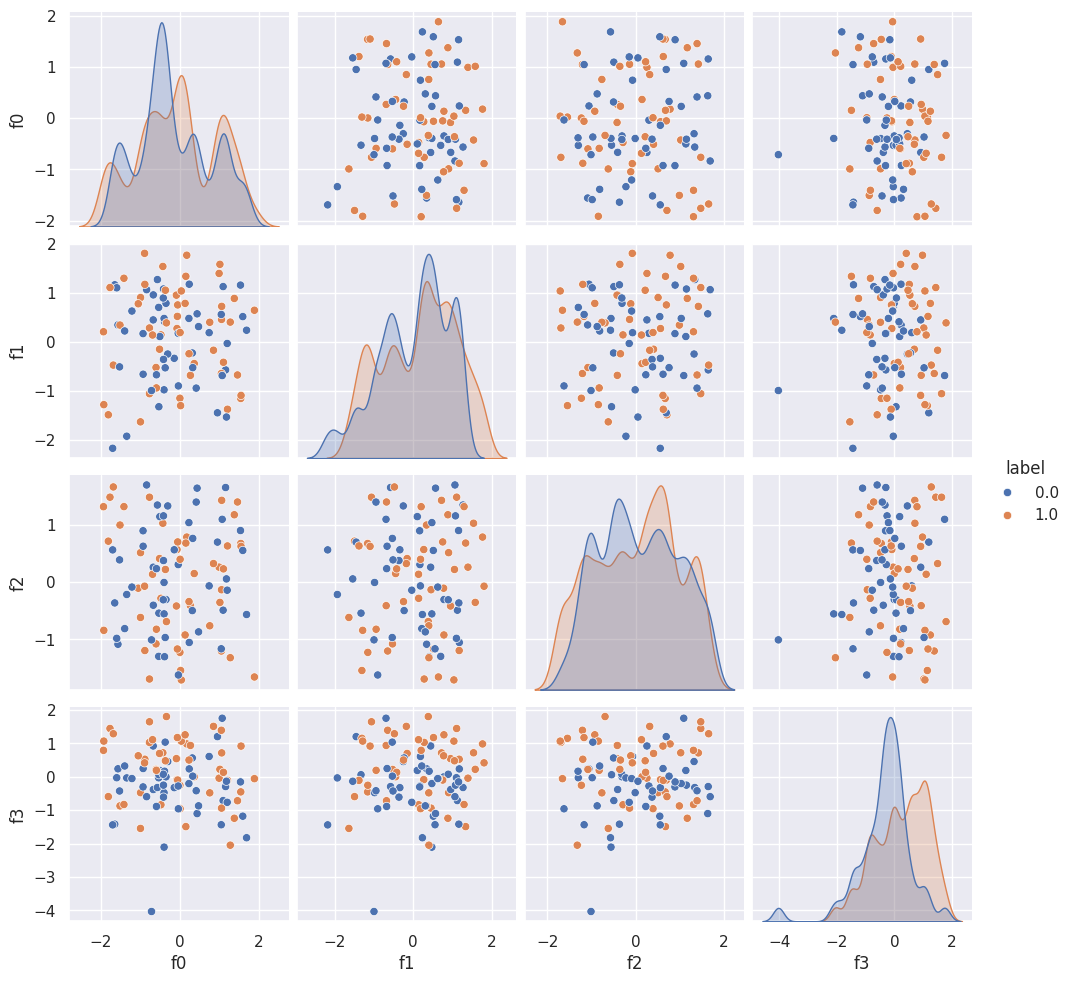

In [25]:
# Muestra la versión actual de la librería seaborn instalada en el entorno
print(sns.__version__)


# Selecciona un subconjunto de características (desde el índice 1 hasta el 5)
# para convertirlo en lista y evitar saturar la visualización con las 29 columnas
cols_to_plot = train_set.columns[1:6].tolist()

# Genera una matriz de gráficos cruzados (pairplot) usando una muestra aleatoria de 100 filas.
# 'hue="label"' diferencia por color las clases (señal vs fondo)
# y 'diag_kws' ajusta el ancho de banda de las curvas de densidad en la diagonal.
pp=sns.pairplot(data=train_set.sample(100)[cols_to_plot], hue='label', diag_kws={'bw': 0.2})

# Línea de ejemplo comentada: muestra cómo se vería si intentaras graficar TODAS las columnas a la vez
#sns.pairplot(train_set.sample(100))

# Renderiza y despliega la figura final en la interfaz del cuaderno
plt.show()

In [26]:
# Aplica un gráfico de densidad de probabilidad bidimensional (KDE)
# únicamente en la mitad inferior de la matriz de gráficos (map_lower).
# - levels=4: Dibuja 4 niveles o líneas de contorno para mostrar la concentración de los datos.
# - color=".2": Define un tono de gris (escala de 0 a 1) para las líneas de contorno.
pp.map_lower(sns.kdeplot, levels=4, color=".2")

# Renderiza y muestra la figura actualizada con los nuevos contornos superpuestos
plt.show(sns)

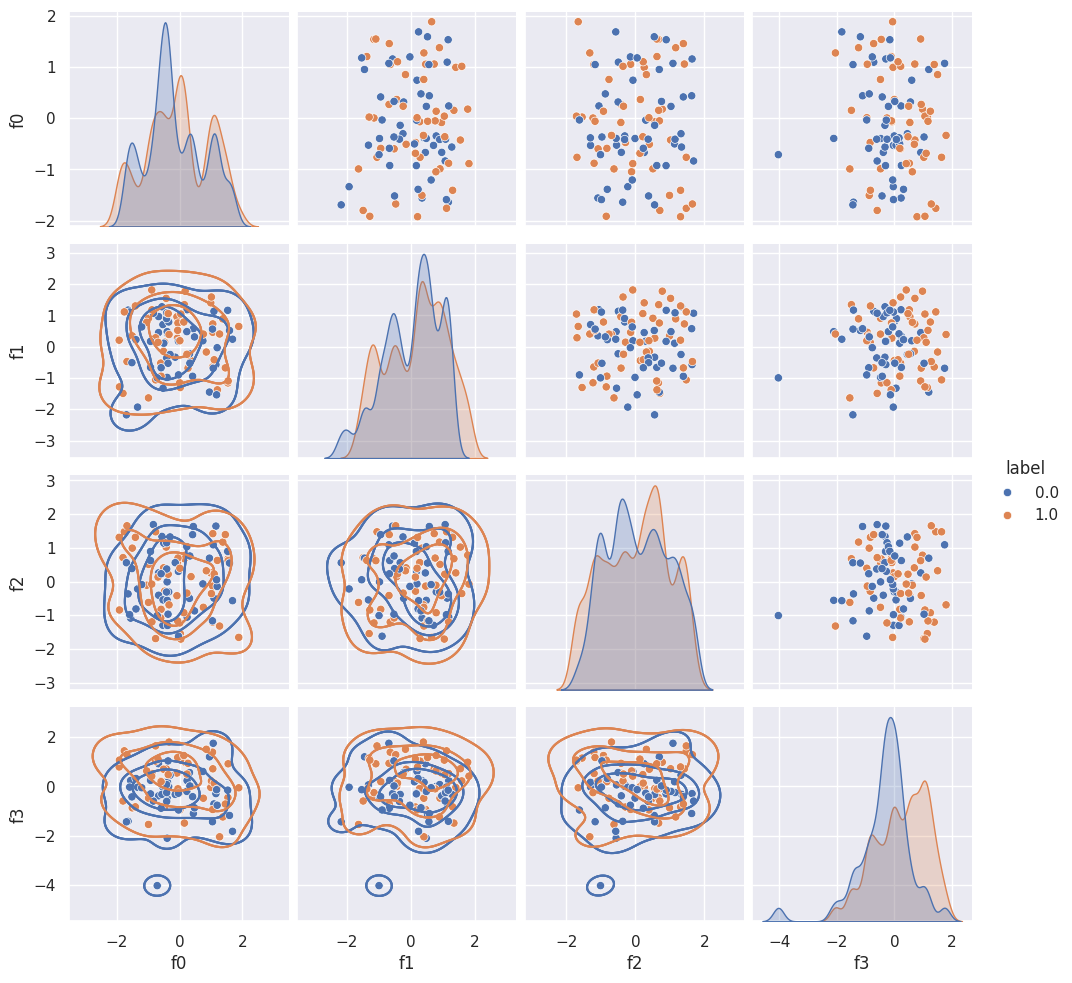

In [28]:
# Aplica el gráfico de densidad KDE en la mitad inferior de la matriz
pp.map_lower(sns.kdeplot, levels=4, color=".2")

# Fuerza a mostrar la figura actualizada utilizando el objeto de la gráfica
display(pp.fig)

#### Correlation matrices

Take a look at the correlation matrices

In [ ]:
def corrmatrix(corr, label):
    ax = sns.heatmap(
        corr,
        vmin=-1., vmax=1., center=0.,
        cmap=sns.diverging_palette(20., 220., n=200, as_cmap=True),
        square=True
    )
    ax.set_xticklabels(
        ax.get_xticklabels(),
        rotation=45,
        horizontalalignment='right'
    );

    ax.set_title('Correlation matrix for %s events' % label)

    plt.show()


corrmatrix(train_set[train_set['label']==1.].corr(), 'signal')
corrmatrix(train_set[train_set['label']==0.].corr(), 'background')


### Preprocess the data

Normally you'd check if it makes sense to preprocess the input features.

Unfortunately, **the HEPmass dataset contains pre-normalized features, so it doesn't make sense to renormalize them**.
You are welcome to check the effect of scalers on other datasets. For reference, you can check [this `scikit-learn` post](https://scikit-learn.org/stable/auto_examples/preprocessing/plot_all_scaling.html) for the python code to apply scalers to input features.

#### Build a parametric neural network

Following the instructions below
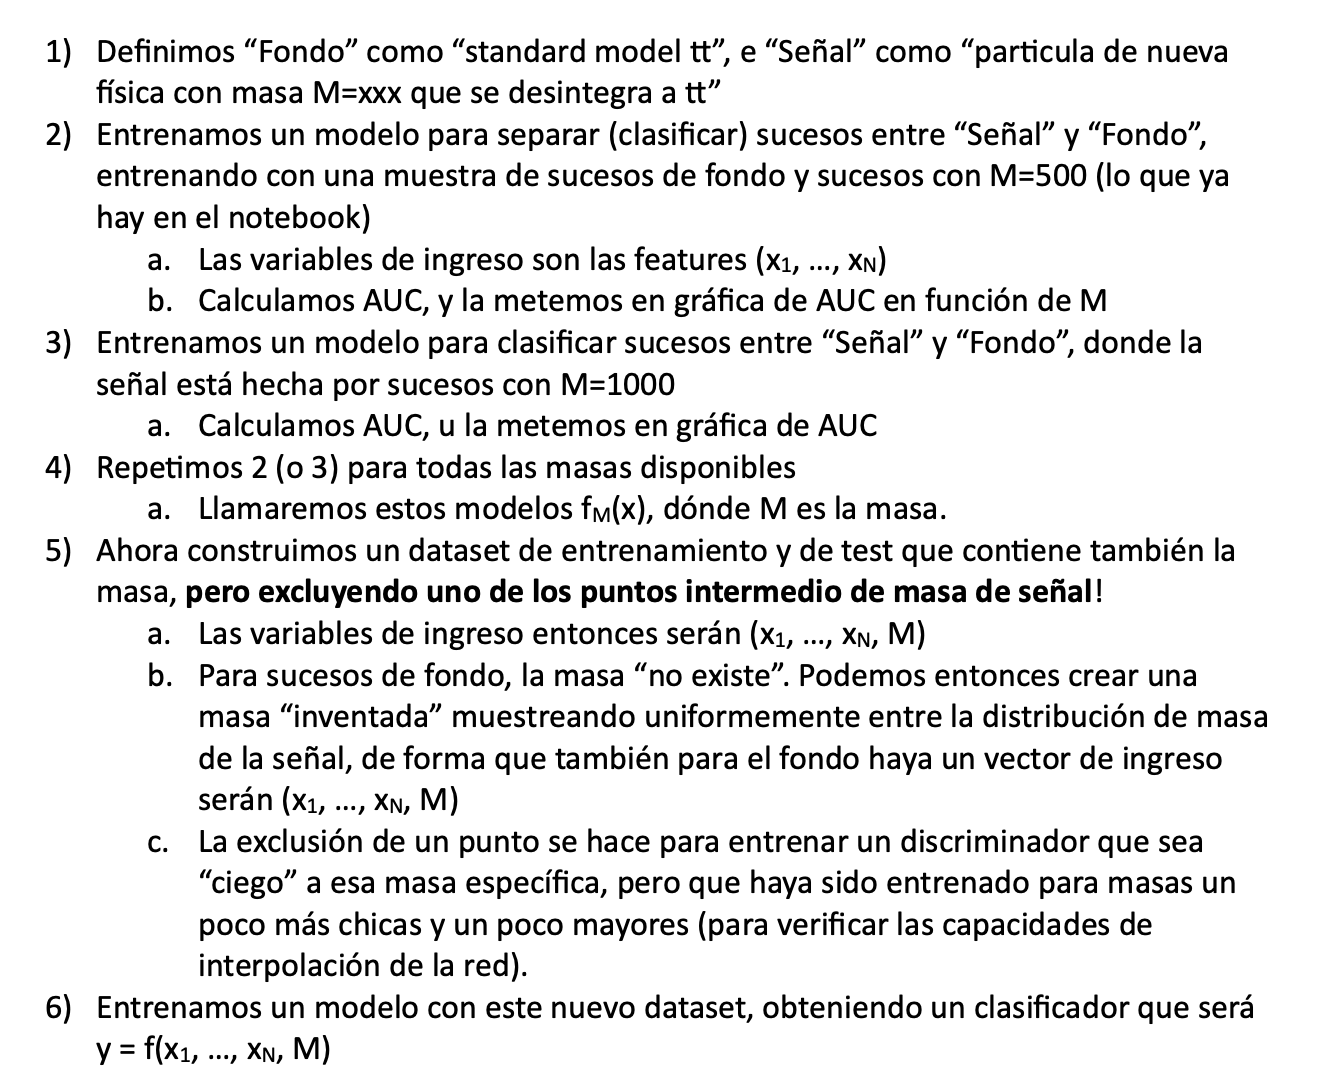

# **Neural network template**

You can use this as a blueprint (it's convenient to wrap the full neural network into a function, for training with different masses etc)

In [ ]:
class StandardNeuralNetwork(nn.Module):
    def __init__(self, ninputs, device=torch.device("cpu")):
        super().__init__()
        self.flatten = nn.Flatten()
        self.linear_relu_stack = nn.Sequential(
            nn.Linear(ninputs, 512),
            nn.ReLU(),
            nn.Linear(512, 128),
            nn.ReLU(),
            nn.Linear(128,64),
            nn.ReLU(),
            nn.Linear(64,8),
            nn.Sigmoid(),
            nn.Linear(8, 1),
            nn.Sigmoid()
        )
        self.device=device
        self.linear_relu_stack.to(self.device)

    def forward(self, x):
        # Pass data through conv1
        y = self.linear_relu_stack(x)
        return y


def neural_network(mass, X_train, y_train, X_test, y_test, dataloader, device, epochs=10, learningRate=0.01):

    model = StandardNeuralNetwork(X_train.shape[1], device)

    loss_fn = torch.nn.CrossEntropyLoss()
    optimizer = torch.optim.SGD(model.parameters(), lr=learningRate) #SGD, Adam
    scheduler = torch.optim.lr_scheduler.ExponentialLR(optimizer, gamma=0.9)

    train_losses=[]
    test_losses=[]
    for t in range(epochs):
        print(f"Epoch {t+1}\n-------------------------------")
        train_loss=train_loop(train_dataloader, model, loss_fn, optimizer, scheduler, device)
        # Train -------------------------------------------------------
        size = len(dataloader.dataset)
        losses=[] # Track the loss function
        # Set the model to training mode
        model.train()
        for (X,y) in tqdm(dataloader):
            # Reset gradients (to avoid their accumulation)
            optimizer.zero_grad()
            # Compute prediction and loss
            yhat = model(X)
            loss = loss_fn(yhat.squeeze(dim=1), y)
            losses.append(loss.detach().cpu())
            # Backpropagation
            loss.backward()
            optimizer.step()

        scheduler.step()
        train_losses.append(np.mean(losses))

        # Test --------------------------------------------------------
        losses=[] # Track the loss function for the test loop
        # Set the model to evaluation mode
        model.eval()
        size = len(dataloader.dataset)
        num_batches = len(dataloader)
        test_loss, correct = 0, 0
        with torch.no_grad():
            for (X,y) in tqdm(dataloader):
                yhat = model(X)
                loss = loss_fn(yhat.squeeze(dim=1), y).item()
                losses.append(loss)
                test_loss += loss

        test_losses.append(np.mean(losses))

        print("Avg train loss", train_loss, ", Avg test loss", test_loss, "Current learning rate", scheduler.get_last_lr())
    print("Done!")
    return model, train_losses, test_losses

In [ ]:
# Example of use

# ... create dataloader for m=500

model_m500, train_losses_m500, test_losses_m500 = neural_network(500, X_train_500, y_train_500, X_test_500, y_test_500, dataloader_500, device, epochs=10, learningRate=0.01):

# Now you can use `model_m500` to make inference, and the losses arrays to e.g. plot them

plt.plot(train_losses_m500, label="Average training loss")
plt.plot(test_losses_m500, label="Average test loss")
plt.title("Training for m=500")
plt.legend(loc="best")